# 01 · Data exploration

What the 2015/16 data looks like before any scouting model, in three questions:

1. **How many minutes do players get?** What a minimum-minutes filter costs, by league,
   position and age, and which position groups players are compared within.
2. **How many minutes before a per-90 number means something?** The split-half reliability
   of each statistic, which sets the filters and how much to trust small samples.
3. **Do the four leagues play, and get recorded, the same way?** Whether players from
   different leagues can be compared on the same scale.

**Scouting pool:** Premier League, La Liga, Serie A and Ligue 1, season 2015/16 (1,517 matches).
StatsBomb's Bundesliga 2015/16 only covers Bayer Leverkusen's matches, so it stays out of the
pool.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups) and
Transfermarkt via [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)
(dates of birth). Only aggregated results are shown, as StatsBomb's licence requires. Tables are
built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from football_scouting.analysis.metrics import LABELS, PER_90, SUMMED, player_match_counts, rates
from football_scouting.analysis.players import pool_player_seasons
from football_scouting.analysis.reliability import (
    minutes_for,
    split_half_reliability,
    stabilisation_minutes,
)
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
COLORS = position_colors(cfg)
GROUPS = [g.code for g in cfg.position_groups]
GROUP_NAMES = {g.code: g.name for g in cfg.position_groups}
COMPARISON_NAMES = {g.code: g.name for g in cfg.comparison_groups}

## 1. How many minutes do players get?

Per-90 numbers from a few hundred minutes are mostly noise, so every comparison of players needs
a minimum-minutes filter. This section measures what each threshold costs: how many players
remain, by league, position group and age.

- **Minutes are real time on the pitch**, stoppage time included. A match lasts about 95 real
  minutes, so 900 minutes is about 9.5 full matches.
- **One row per player.** A player who changed clubs within the pool counts once, with minutes
  summed over the clubs; minutes outside the pool (Bundesliga) are left out.
- **Position group** is the group where the player spent the most minutes.
- **Age** on 30 June 2016, the end of the season, from the Transfermarkt date of birth.

In [2]:
AGE_ON = date(2016, 6, 30)
THRESHOLDS = [450, 900, 1350, 1800]

players = pool_player_seasons(con, cfg, age_on=AGE_ON)
team_seasons = con.sql("""
    WITH sides AS (
        SELECT m.duration_seconds, unnest([m.home_team_id, m.away_team_id]) AS team_id
        FROM matches m WHERE m.scouting_pool)
    SELECT team_id, count(*) AS matches, sum(duration_seconds) / 60 AS minutes
    FROM sides GROUP BY team_id
""").df()

print(f"{len(players):,} players played in the pool, {players.minutes.sum() / 1e6:.2f}M minutes.")
print(
    f"A team's season lasts {team_seasons.minutes.min():,.0f} to "
    f"{team_seasons.minutes.max():,.0f} real minutes (median {team_seasons.minutes.median():,.0f})."
)

2,176 players played in the pool, 3.16M minutes.
A team's season lasts 3,479 to 3,691 real minutes (median 3,612).


### 1.1 By league

Minutes per player (quartiles) and the number of players at or above each threshold (share of
the league's players in brackets).

In [3]:
def threshold_table(df: pd.DataFrame, by: str, total: str | None = None) -> pd.DataFrame:
    def summarise(m: pd.Series) -> pd.Series:
        row = {
            "players": len(m),
            "p25": m.quantile(0.25),
            "median": m.median(),
            "p75": m.quantile(0.75),
        }
        for t in THRESHOLDS:
            n = int((m >= t).sum())
            row[f"≥ {t:,}"] = f"{n:,} ({n / len(m):.0%})"
        return pd.Series(row)

    out = df.groupby(by, observed=True)["minutes"].apply(summarise).unstack()
    if total:
        out.loc[total] = summarise(df["minutes"])
    quartiles = ["p25", "median", "p75"]
    out[quartiles] = out[quartiles].astype(float).round(-1).astype(int)
    return out.rename_axis(None)


threshold_table(players, "league", total="All four leagues")

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800"
La Liga,533,570,1380,2330,423 (79%),344 (65%),268 (50%),203 (38%)
Ligue 1,565,470,1300,2230,429 (76%),343 (61%),272 (48%),204 (36%)
Premier League,537,390,1360,2420,390 (73%),332 (62%),270 (50%),222 (41%)
Serie A,541,510,1380,2280,418 (77%),347 (64%),276 (51%),212 (39%)
All four leagues,2176,490,1340,2300,"1,660 (76%)","1,366 (63%)","1,086 (50%)",841 (39%)


### 1.2 By position group

The same thresholds per position group. `fewest in a league` is the smallest number of players
of that group at 900 minutes or more in any single league: the sample a within-league
percentile would rest on.

In [4]:
by_group = threshold_table(players, "position_group")
by_group.index = [f"{c} · {GROUP_NAMES[c]}" for c in by_group.index]
fewest = (
    players[players.minutes >= 900]
    .groupby(["position_group", "league"], observed=True)
    .size()
    .groupby(level=0, observed=True)
    .min()
)
by_group["fewest in a league (≥ 900)"] = fewest.to_numpy()
by_group

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800",fewest in a league (≥ 900)
GK · Goalkeeper,182,290,1100,3020,122 (67%),100 (55%),86 (47%),77 (42%),23
CB · Centre-back,348,900,1890,2640,296 (85%),261 (75%),216 (62%),181 (52%),61
FB · Full-back / wing-back,391,620,1370,2240,315 (81%),253 (65%),197 (50%),148 (38%),59
CM · Central midfield,470,560,1500,2380,369 (79%),307 (65%),254 (54%),204 (43%),69
AM · Attacking midfield,85,210,840,1980,57 (67%),37 (44%),32 (38%),28 (33%),7
W · Wide midfield / winger,408,370,1150,1920,295 (72%),243 (60%),176 (43%),113 (28%),45
CF · Centre-forward,292,380,1090,2020,206 (71%),165 (57%),125 (43%),90 (31%),37


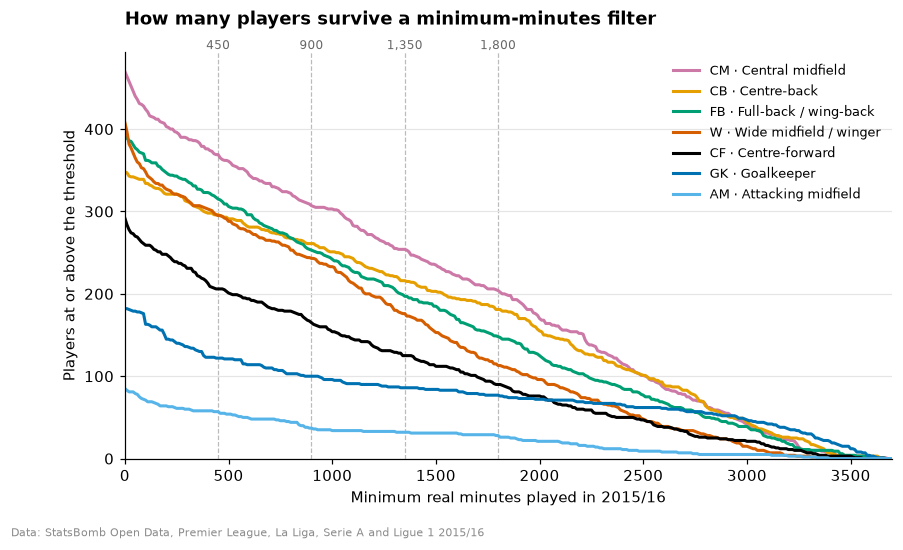

In [5]:
grid = np.arange(0, 3701, 10)
fig, ax = plt.subplots(figsize=(9, 4.8))
remaining = {
    g: [(players.loc[players.position_group == g, "minutes"] >= x).sum() for x in grid]
    for g in GROUPS
}
for g in sorted(GROUPS, key=lambda g: -remaining[g][90]):
    ax.plot(grid, remaining[g], color=COLORS[g], lw=2, label=f"{g} · {GROUP_NAMES[g]}")
for t in THRESHOLDS:
    ax.axvline(t, color="#BBBBBB", lw=0.8, ls="--", zorder=0)
    ax.text(t, ax.get_ylim()[1], f"{t:,}", ha="center", va="bottom", fontsize=8, color="#666666")
ax.set_xlim(0, 3700)
ax.set_ylim(0)
ax.set_xlabel("Minimum real minutes played in 2015/16")
ax.set_ylabel("Players at or above the threshold")
ax.set_title("How many players survive a minimum-minutes filter", pad=18)
ax.legend(loc="upper right", fontsize=8.5)
credit(fig, "Data: StatsBomb Open Data, Premier League, La Liga, Serie A and Ligue 1 2015/16")
plt.show()

### 1.3 How pure are the position groups?

For players with 900 minutes or more: the share of their minutes spent in each group (rows: the
player's primary group). A low diagonal means the group mixes roles.

In [6]:
regulars = players[players.minutes >= 900]
group_cols = [f"minutes_{g.lower()}" for g in GROUPS]
mix = regulars.groupby("position_group", observed=True)[group_cols].sum()
mix = mix.div(mix.sum(axis=1), axis=0).mul(100).round().astype(int)
mix.columns = GROUPS
mix.index = [f"{c} (n={n})" for c, n in regulars.position_group.value_counts()[mix.index].items()]
mix

,GK,CB,FB,CM,AM,W,CF
GK (n=100),100,0,0,0,0,0,0
CB (n=261),0,95,4,1,0,0,0
FB (n=253),0,4,92,1,0,3,0
CM (n=307),0,1,1,90,4,3,0
AM (n=37),0,0,0,13,64,17,6
W (n=243),0,0,2,5,8,78,7
CF (n=165),0,0,0,1,3,7,89


### 1.4 Merging attacking midfield: with the wingers, or split between midfield and attack?

Attacking midfield is too small to compare on its own (37 players at 900 minutes). Two ways to
merge it:

- **Option A:** attacking midfield + wingers ("attacking midfielders and wingers", the grouping
  of StatsBomb's radar templates);
- **Option B:** attacking midfield + central midfield ("midfielders") and wingers +
  centre-forwards ("forwards").

A merge makes sense if the merged players **move between those positions** (test 1) and **do
similar things on the ball** (test 2). Both tests use outfield players with 900 minutes or more.

**Test 1: who swaps positions with whom.** Minutes played across each boundary: minutes that
players of one group spent in the other, both ways (thousands of minutes).

In [7]:
counts = player_match_counts(con)
season = rates(counts.groupby("player_id")[SUMMED].sum())
outfield = players[(players.minutes >= 900) & (players.position_group != "GK")].set_index(
    "player_id"
)
group = outfield.position_group.astype(str)

FOCUS = ["CM", "AM", "W", "CF"]
spent = outfield.groupby(group)[[f"minutes_{g.lower()}" for g in FOCUS]].sum().loc[FOCUS]
spent.columns = FOCUS
across = spent + spent.T  # X players' minutes in Y plus Y players' minutes in X
OPTIONS = {"A": [("AM", "W")], "B": [("AM", "CM"), ("W", "CF")]}
pairs = [("AM", "W"), ("AM", "CM"), ("W", "CF"), ("CM", "W"), ("AM", "CF"), ("CM", "CF")]
pd.DataFrame(
    {
        "minutes across (thousands)": [across.loc[a, b] / 1000 for a, b in pairs],
        "kept inside a group by": [
            " and ".join(o for o, ps in OPTIONS.items() if (a, b) in ps) or "neither"
            for a, b in pairs
        ],
    },
    index=[f"{a} ↔ {b}" for a, b in pairs],
).round(1)

,minutes across (thousands),kept inside a group by
AM ↔ W,50.7,A
AM ↔ CM,33.8,B
W ↔ CF,54.8,B
CM ↔ W,42.2,neither
AM ↔ CF,15.4,neither
CM ↔ CF,4.9,neither


Both options keep a large share of the swaps inside a group: option A the AM ↔ W swaps,
option B the AM ↔ CM and W ↔ CF swaps (more minutes in total, because wingers and
centre-forwards swap a lot in front threes). Seen from attacking midfield, its players spend
17% of their minutes on the wing and 13% in central midfield (table 1.3): a slight lean to
option A, so test 1 alone does not decide.

**Test 2: who plays like whom.** Each player's per-90 profile over 15 on-ball and defensive
actions, standardised across all outfield players (z-scores: 0 is the outfield average, ±1 is
one standard deviation). The map shows each group's average profile.

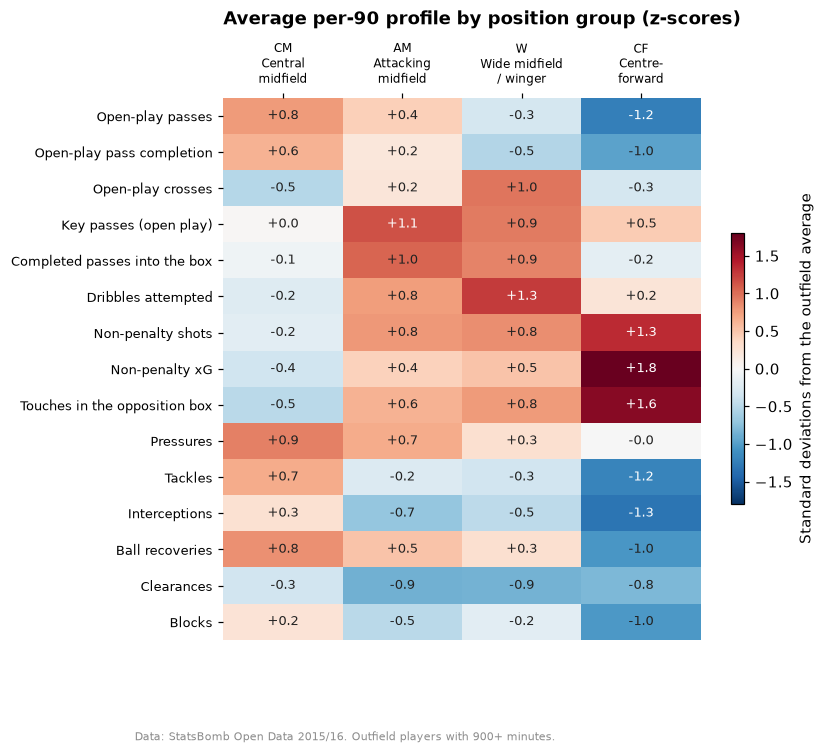

In [8]:
ACTIONS = [
    "passes", "pass_completion", "crosses", "key_passes", "passes_into_box", "dribbles",
    "shots", "xg", "touches_in_box", "pressures", "tackles", "interceptions", "recoveries",
    "clearances", "blocks",
]  # fmt: skip
LOCATION = ["mean_x", "mean_width"]


def zscores(columns: list[str]) -> pd.DataFrame:
    x = season.loc[outfield.index, columns]
    return (x - x.mean()) / x.std()


z = zscores(ACTIONS)
profile = z.groupby(group).mean().loc[FOCUS].T

fig, ax = plt.subplots(figsize=(7, 6.4))
im = ax.imshow(profile, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
for (r, c), v in np.ndenumerate(profile.to_numpy()):
    ax.text(
        c,
        r,
        f"{v:+.1f}",
        ha="center",
        va="center",
        fontsize=8.5,
        color="white" if abs(v) > 1.1 else "#222222",
    )
SHORT = {
    "CM": "Central\nmidfield",
    "AM": "Attacking\nmidfield",
    "W": "Wide midfield\n/ winger",
    "CF": "Centre-\nforward",
}
ax.set_xticks(range(len(FOCUS)), [f"{g}\n{SHORT[g]}" for g in FOCUS], fontsize=8)
ax.set_yticks(range(len(ACTIONS)), [LABELS[a] for a in ACTIONS], fontsize=8.5)
ax.xaxis.tick_top()
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Average per-90 profile by position group (z-scores)", pad=48)
fig.colorbar(im, ax=ax, shrink=0.5, label="Standard deviations from the outfield average")
credit(fig, "Data: StatsBomb Open Data 2015/16. Outfield players with 900+ minutes.")
plt.show()

Three checks on the profiles:

- **distance between group averages** (Euclidean, in standard deviations), with and without
  two location features (average touch position up the pitch and distance from the centre
  line), which do not change the answer;
- **closest group** for each attacking midfielder and each winger, leaving their own group out;
- **spread inside each group** (average distance of its players to the group average) before
  and after each merge: a merge of unlike players widens it.

In [9]:
def distances(z: pd.DataFrame) -> pd.Series:
    c = z.groupby(group).mean()
    return pd.Series({f"{a} – {b}": np.linalg.norm(c.loc[a] - c.loc[b]) for a, b in pairs})


display(
    pd.DataFrame(
        {"actions": distances(z), "actions + location": distances(zscores(ACTIONS + LOCATION))}
    )
    .round(2)
    .rename_axis("distance between")
)

centroids = z.groupby(group).mean()
closest = {}
for g in ["AM", "W"]:
    others = [o for o in FOCUS if o != g]
    d = pd.DataFrame({o: np.linalg.norm(z[group == g] - centroids.loc[o], axis=1) for o in others})
    closest[f"{g} players (n={len(d)})"] = d.idxmin(axis=1).value_counts(normalize=True)
display(
    pd.DataFrame(closest)
    .T.reindex(columns=FOCUS)
    .mul(100)
    .round()
    .fillna(0)
    .astype(int)
    .rename_axis("% closest to")
)

MERGES = {
    "No merge": {},
    "Option A": {"AM": "AM+W", "W": "AM+W"},
    "Option B": {"AM": "AM+CM", "CM": "AM+CM", "W": "W+CF", "CF": "W+CF"},
}
spread = {}
for option, mapping in MERGES.items():
    label = group.replace(mapping)
    spread[option] = z.groupby(label).apply(lambda d: np.linalg.norm(d - d.mean(), axis=1).mean())
pd.DataFrame(spread).round(2).rename_axis("spread inside")

,actions,actions + location
distance between,,
AM – W,1.54,1.77
AM – CM,3.14,3.29
W – CF,3.42,3.60
CM – W,3.85,4.21
AM – CF,3.79,3.83
CM – CF,5.53,5.70


,CM,AM,W,CF
% closest to,,,,
AM players (n=37),16,0,81,3
W players (n=243),9,74,0,16


,No merge,Option A,Option B
spread inside,,,
AM,2.79,NaN,NaN
AM+CM,NaN,NaN,2.87
AM+W,NaN,3.09,NaN
CB,2.02,2.02,2.02
CF,2.45,2.45,NaN
CM,2.72,2.72,NaN
FB,2.51,2.51,2.51
W,3.08,NaN,NaN
W+CF,NaN,NaN,3.28


**Result: option A.** Attacking midfielders play like wingers, not like central midfielders:
the AM and W profiles are 1.5 standard deviations apart, against 3.1 for AM–CM and 3.4 for
W–CF, and 81% of attacking midfielders are closest to the winger profile. Merging AM into W
leaves the winger group's spread unchanged (3.08 → 3.09), while option B widens both merged
groups, most of all the forwards (centre-forwards 2.45 → 3.28): it would rank wingers
against strikers on shots and xG. Wingers and centre-forwards do swap positions often (test
1), but they do different jobs, so they stay apart.

Players are compared within six groups (`comparison_groups` in `config/pipeline.yaml`):
goalkeepers, centre-backs, full-backs, central midfielders, **attacking midfielders and
wingers**, centre-forwards.

### 1.5 By age

Share of players in each minutes band, by age on 30 June 2016. Young players are where a
recruitment back-test has the most to gain, and also where a minutes filter cuts hardest.

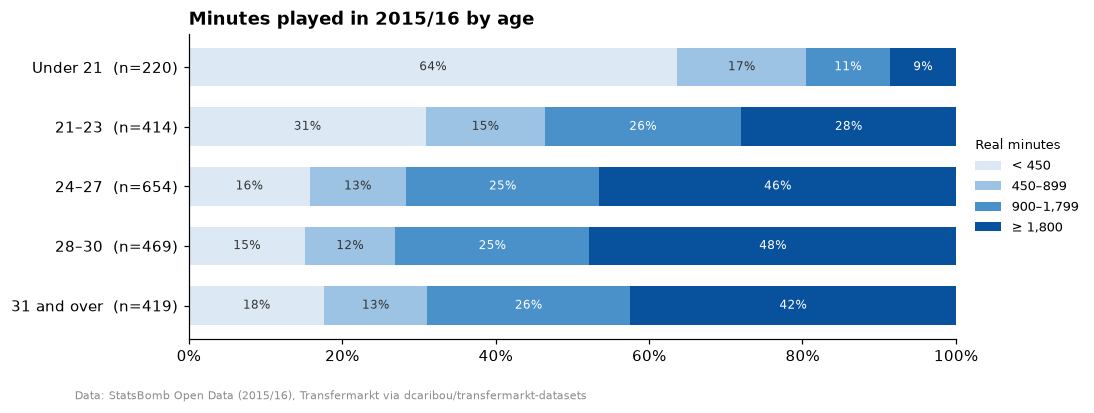

In [10]:
AGE_BANDS = [0, 21, 24, 28, 31, 99]
AGE_LABELS = ["Under 21", "21–23", "24–27", "28–30", "31 and over"]
MINUTE_BANDS = [0, 450, 900, 1800, np.inf]
MINUTE_LABELS = ["< 450", "450–899", "900–1,799", "≥ 1,800"]

aged = players.dropna(subset=["age"]).assign(
    age_band=lambda d: pd.cut(d.age, AGE_BANDS, right=False, labels=AGE_LABELS),
    minutes_band=lambda d: pd.cut(d.minutes, MINUTE_BANDS, right=False, labels=MINUTE_LABELS),
)
shares = pd.crosstab(aged.age_band, aged.minutes_band, normalize="index")
band_sizes = aged.age_band.value_counts().reindex(AGE_LABELS)

fig, ax = plt.subplots(figsize=(9, 3.6))
blues = ["#DCE9F5", "#9CC3E4", "#4A90C9", "#08519C"]
left = np.zeros(len(shares))
for band, colour in zip(MINUTE_LABELS, blues, strict=True):
    ax.barh(range(len(shares)), shares[band], left=left, color=colour, label=band, height=0.65)
    for i, (x0, w) in enumerate(zip(left, shares[band], strict=True)):
        if w >= 0.06:
            text_colour = "white" if band in MINUTE_LABELS[2:] else "#333333"
            ax.text(
                x0 + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8, color=text_colour
            )
    left += shares[band].to_numpy()
ax.set_yticks(range(len(shares)), [f"{a}  (n={band_sizes[a]})" for a in shares.index])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(False)
ax.set_title("Minutes played in 2015/16 by age")
ax.legend(
    title="Real minutes",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    fontsize=8.5,
    title_fontsize=8.5,
    alignment="left",
)
credit(fig)
plt.show()

In [11]:
threshold_table(aged, "age_band")

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800"
Under 21,220,50,220,770,80 (36%),43 (20%),28 (13%),19 (9%)
21–23,414,300,1010,1950,286 (69%),222 (54%),164 (40%),116 (28%)
24–27,654,810,1670,2550,551 (84%),469 (72%),382 (58%),304 (46%)
28–30,469,840,1720,2450,398 (85%),343 (73%),286 (61%),224 (48%)
31 and over,419,650,1460,2400,345 (82%),289 (69%),226 (54%),178 (42%)


**Where does "young" end?** The same shares by year of age (age in whole years on 30 June 2016):

In [12]:
YEAR_BANDS = [0, 20, 21, 22, 23, 24, 25, 28, 31, 99]
YEAR_LABELS = ["Under 20", "20", "21", "22", "23", "24", "25–27", "28–30", "31 and over"]

by_year = aged.groupby(
    pd.cut(aged.age, YEAR_BANDS, right=False, labels=YEAR_LABELS), observed=True
)["minutes"]
young = aged[aged.age < 23]
print(
    f"Under 23: {len(young)} players, {(young.minutes >= 900).sum()} with 900+ minutes and "
    f"{young.minutes.between(450, 900, inclusive='left').sum()} more with 450–899."
)
pd.DataFrame(
    {
        "players": by_year.size(),
        "≥ 450 minutes": by_year.apply(lambda m: f"{(m >= 450).mean():.0%}"),
        "≥ 900 minutes": by_year.apply(lambda m: f"{(m >= 900).mean():.0%}"),
    }
).T.rename_axis(None, axis=1)

Under 23: 482 players, 175 with 900+ minutes and 70 more with 450–899.


,Under 20,20,21,22,23,24,25–27,28–30,31 and over
players,110,110,121,141,152,151,503,469,419
≥ 450 minutes,29%,44%,57%,68%,80%,80%,85%,85%,82%
≥ 900 minutes,16%,23%,45%,55%,59%,67%,73%,73%,69%


The share of players reaching 900 minutes climbs through the early twenties (23% at 20, 45% at
21, 55% at 22, 59% at 23) and levels off at 67–73% from 24. **Under 23**, also football's usual
young-player limit, marks the players a 900-minute filter treats hardest. Lowering their
threshold to 450 minutes adds 70 players to the 175 under-23s who pass 900.

### 1.6 Players who changed clubs

Summing minutes over clubs only matters for the few players who moved during the season.

In [13]:
moves = players.assign(
    move=np.select(
        [players.n_teams == 1, players.n_leagues == 1],
        ["One club", "Two clubs, same league"],
        "Two clubs, two leagues",
    )
)
pd.DataFrame(
    {
        "players": moves.groupby("move").size(),
        "≥ 900 summed": moves[moves.minutes >= 900].groupby("move").size(),
        "≥ 900 only when summed": moves[(moves.minutes >= 900) & (moves.max_team_minutes < 900)]
        .groupby("move")
        .size(),
    }
).fillna(0).astype(int).rename_axis(None)

,players,≥ 900 summed,≥ 900 only when summed
One club,2073,1289,0
"Two clubs, same league",65,47,8
"Two clubs, two leagues",38,30,5


### 1.7 Can percentiles be computed within each league?

A percentile is only as precise as the group it is computed in. If a player's true standing is
the 80th percentile, the percentile measured among n players has a 95% margin of about
±1.96·√(0.8·0.2/n): ±30 points with 7 players, ±8 with 100. The table counts players with 900
minutes or more per comparison group and league.

In [14]:
regulars = players[players.minutes >= 900]
n = regulars.pivot_table(
    index="comparison_group",
    columns="league",
    values="player_id",
    aggfunc="count",
    observed=True,
)
am_alone = regulars[regulars.position_group == "AM"].groupby("league").size()
n.loc["AM alone (not used)"] = am_alone
n["All four leagues"] = n.sum(axis=1)


def margin(k):
    return 1.96 * np.sqrt(0.8 * 0.2 / k) * 100


leagues_only = n.drop(columns="All four leagues")
samples = pd.DataFrame(
    {
        "smallest league": leagues_only.min(axis=1),
        "± points (smallest league)": margin(leagues_only.min(axis=1)),
        "all four leagues": n["All four leagues"],
        "± points (four leagues)": margin(n["All four leagues"]),
    }
)
display(n.rename_axis(None))
samples.round(0).astype(int).rename_axis(None)

league,La Liga,Ligue 1,Premier League,Serie A,All four leagues
GK,23,27,27,23,100
CB,62,68,61,70,261
FB,66,65,59,63,253
CM,70,77,69,91,307
AMW,81,68,79,52,280
CF,42,38,37,48,165
AM alone (not used),8,9,13,7,37


,smallest league,± points (smallest league),all four leagues,± points (four leagues)
GK,23,16,100,8
CB,61,10,261,5
FB,59,10,253,5
CM,69,9,307,4
AMW,52,11,280,5
CF,37,13,165,6
AM alone (not used),7,30,37,13


Within a single league, goalkeepers (23 to 27 per league) and centre-forwards (37 to 48)
would have percentile margins of ±13 to ±16 points, and attacking midfield alone ±30. Pooling
the four leagues brings every group to ±8 points or better. **Percentiles are computed over the
four leagues together**; section 3 checks whether the leagues can share one scale.

### What section 1 shows

- **The leagues are alike in playing time.** Each has about 540 players who played, with a
  median of about 1,350 minutes. At 900 minutes, 61–65% of each league's players remain, so a
  threshold does not favour any league.
- **The cost of a threshold falls on a few position groups.** Attacking midfield is small and
  mixed (85 players, 37 at 900 minutes, as few as 7 in a league); it plays like the wingers and
  is merged with them (1.4). Goalkeepers split into starters who play almost everything and
  back-ups who barely play.
- **Age is where a threshold cuts hardest.** At 900 minutes, 20% of under-21 players remain
  (43 of 220), against 72% of those aged 24–27, and the share keeps rising until about 23
  (1.5).
- **Mid-season moves barely matter.** 103 players changed clubs within the pool; summing their
  minutes brings 13 more players above 900 minutes.
- **Within-league percentiles would be too coarse** for goalkeepers and centre-forwards (1.7).

**Decisions (2026-10-11):**

1. Players are compared from **900 real minutes**; players **under 23** on 30 June 2016 from
   **450 minutes** (1.5). Small samples are handled by shrinking per-90 numbers towards the
   group average (section 2).
2. Six **comparison groups**, attacking midfield merged with the wingers (1.4).
3. **Percentiles over the four leagues together** (1.7).
4. **Minutes summed over clubs** for players who moved mid-season.
5. Shinji Okazaki, the only pool player without a Transfermarkt date of birth, gets it from a
   public source (`config/date_of_birth_overrides.csv`).

## 2. How many minutes before a per-90 number means something?

A player's per-90 rate mixes skill and chance. **Split-half reliability** measures how much of
it is skill: deal each player's matches at random into two halves of M minutes each and
correlate the two halves' rates across players. A correlation of 1 means the rate is all
player; 0 means it is all chance.

- **Players:** outfield players with 1,800 minutes or more (764), so both halves can reach
  900 minutes. Rates are centred within comparison group and league first, so the test asks
  whether a player stands out from comparable players, not whether strikers shoot more than
  centre-backs (and section 3 shows the leagues record some events differently).
- **Random halves, 50 draws**, not first vs second half of the season: a chronological split
  would mix chance with real change (form, injuries, new coaches).
- **Model:** reliability follows r = M / (M + K) closely. **K is the number of minutes at which a
  rate is half skill, half chance**, and M / (M + K) is the weight a player's own rate deserves
  against the group average after M minutes: the shrinkage rule for small samples.

In [15]:
REL_METRICS = [*PER_90, "pass_completion", "dribble_success"]
MINUTES_GRID = [180, 270, 360, 450, 600, 750, 900]

long_season = players[(players.minutes >= 1800) & (players.comparison_group != "GK")]
context = (long_season.comparison_group.astype(str) + " | " + long_season.league).set_axis(
    long_season.player_id
)
curve = split_half_reliability(
    counts[counts.player_id.isin(long_season.player_id)],
    context,
    REL_METRICS,
    MINUTES_GRID,
    draws=50,
)
K = stabilisation_minutes(curve, REL_METRICS)
mean_curve = curve.groupby("target")[["players", "minutes", *REL_METRICS]].mean()
print(
    f"{len(long_season)} players; {mean_curve.players.min():.0f} reach 900 minutes in both halves."
)

# Model check: if r = M / (M + K) holds, K = M (1 - r) / r is the same at every M.
implied = mean_curve[REL_METRICS].rdiv(1).sub(1).mul(mean_curve.minutes, axis=0)
print(
    "K implied at each M varies by at most "
    f"{(implied.max() / implied.min() - 1).drop('dribble_success').max():.0%} "
    "(dribble success excluded: it is almost pure noise)."
)

764 players; 702 reach 900 minutes in both halves.
K implied at each M varies by at most 10% (dribble success excluded: it is almost pure noise).


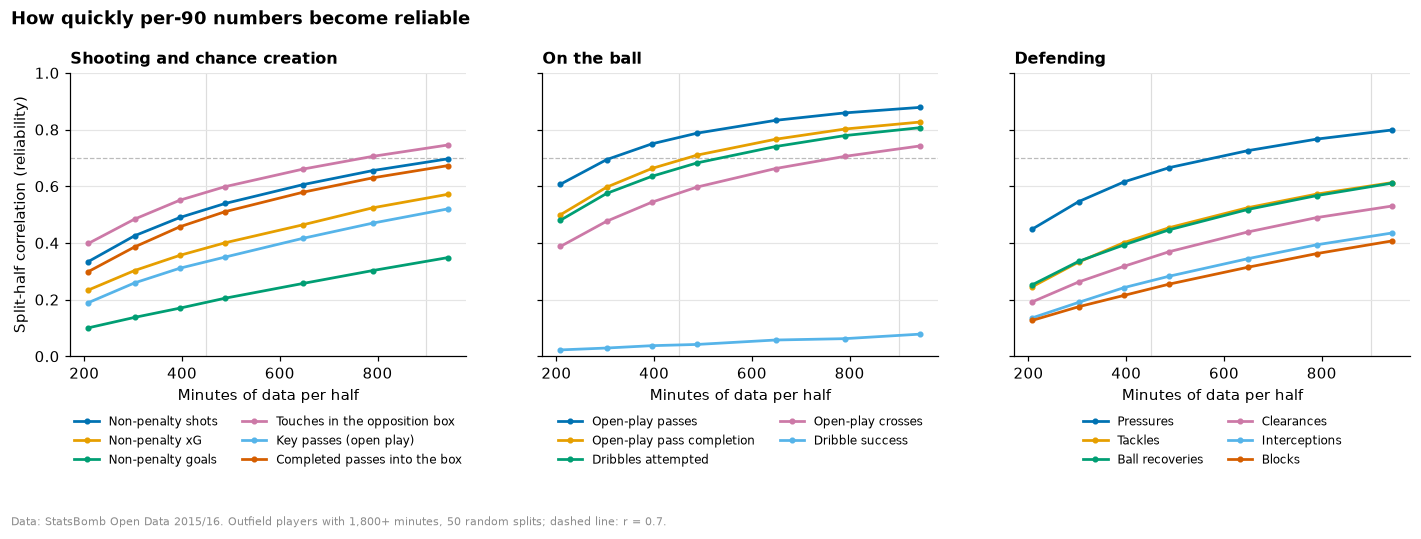

In [16]:
FAMILIES = {
    "Shooting and chance creation": [
        "shots", "xg", "goals", "touches_in_box", "key_passes", "passes_into_box",
    ],
    "On the ball": ["passes", "pass_completion", "dribbles", "crosses", "dribble_success"],
    "Defending": ["pressures", "tackles", "recoveries", "clearances", "interceptions", "blocks"],
}  # fmt: skip

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for ax, (family, metrics) in zip(axes, FAMILIES.items(), strict=True):
    for colour, m in zip(OKABE_ITO, metrics, strict=False):
        ax.plot(
            mean_curve.minutes,
            mean_curve[m],
            marker="o",
            ms=3,
            lw=1.8,
            color=colour,
            label=LABELS[m],
        )
    ax.axhline(0.7, color="#BBBBBB", lw=0.8, ls="--", zorder=0)
    for t in (450, 900):
        ax.axvline(t, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_title(family, fontsize=10.5)
    ax.set_xlabel("Minutes of data per half")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8, ncol=2)
axes[0].set_ylabel("Split-half correlation (reliability)")
fig.suptitle(
    "How quickly per-90 numbers become reliable", x=0.01, ha="left", fontweight="bold", fontsize=12
)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Outfield players with 1,800+ minutes, "
    "50 random splits; dashed line: r = 0.7.",
)
fig.tight_layout()
plt.show()

In [17]:
reliability = pd.DataFrame(
    {
        "K: minutes for r = 0.5": K,
        "r at 450 minutes": 450 / (450 + K),
        "r at 900 minutes": 900 / (900 + K),
        "minutes for r = 0.7": minutes_for(0.7, K),
    }
).sort_values("K: minutes for r = 0.5")
reliability.index = [LABELS[m] for m in reliability.index]
reliability.round(
    {
        "K: minutes for r = 0.5": -1,
        "r at 450 minutes": 2,
        "r at 900 minutes": 2,
        "minutes for r = 0.7": -1,
    }
)

,K: minutes for r = 0.5,r at 450 minutes,r at 900 minutes,minutes for r = 0.7
Open-play passes,130.0,0.77,0.87,310.0
Open-play pass completion,200.0,0.69,0.82,470.0
Dribbles attempted,230.0,0.67,0.80,530.0
Pressures,250.0,0.65,0.78,580.0
Touches in the opposition box,320.0,0.58,0.74,760.0
Open-play crosses,330.0,0.58,0.73,770.0
Non-penalty shots,410.0,0.52,0.68,970.0
Completed passes into the box,470.0,0.49,0.66,1100.0
Tackles,600.0,0.43,0.60,1390.0
Ball recoveries,610.0,0.43,0.60,1410.0


### What section 2 shows

- **Volume and style numbers settle fast.** Passes (K ≈ 130 minutes), pass completion,
  dribbles and pressures are about 80% reliable at 900 minutes and two-thirds reliable at 450.
- **The numbers scouts care most about settle slowly.** At 900 minutes non-penalty xG is about
  0.56 reliable and key passes 0.50; reaching 0.7 takes about 1,700 and 2,100 minutes.
- **Goals are mostly chance over one season** (0.33 at 900 minutes; 4,000+ minutes for 0.7),
  which is why xG, not goals, should rank finishers' output. **Dribble success rate is almost
  pure noise** (0.08 at 900 minutes) and should not rank players.
- **Interceptions and blocks** are weakly reliable even at 900 minutes (about 0.4), partly
  because of how they are recorded (section 3).

So the 900-minute filter does not make every number trustworthy on its own: below about
r = 0.7, a raw per-90 rank rewards luck. **Shrinking each rate towards the comparison group's
average with weight M / (M + K)**, metric by metric, uses the table above directly.

**Decisions (2026-10-11):**

1. **Every player's** per-90 rates and ratios are shrunk towards the comparison group's average
   with weight M / (M + K), using each metric's K from the table above. Regulars included: at
   900 minutes, xG and key passes are still about half chance.
2. **Goals and dribble success rate do not rank players.** Non-penalty xG stands in for goals.

## 3. Do the four leagues play, and get recorded, the same way?

Pooling the leagues (section 1.7) assumes a per-90 number means the same in each. Two things
can break that: **style** (a league that presses more gives every player more pressures) and
**recording** (if events are coded differently, numbers differ with no football reason).

### 3.1 Team numbers per league

Per team and match, per 90 real minutes of match. η² is the share of the variation between
team-matches explained by the league (0 = none).

In [18]:
team = (
    counts.groupby(["match_id", "competition_id", "team_id"])[SUMMED].sum().reset_index()
    .merge(con.sql("""
        SELECT m.match_id, m.duration_seconds / 60 AS match_minutes, c.competition_name AS league
        FROM matches m JOIN competitions c USING (competition_id, season_id)
        WHERE m.scouting_pool""").df(), on="match_id")
    .merge(con.sql("SELECT match_id, team_id, count(*) AS fouls FROM fouls_committed GROUP BY ALL")
           .df(), on=["match_id", "team_id"], how="left")
    .fillna({"fouls": 0})
)  # fmt: skip
TEAM_METRICS = {
    "match_minutes": "Match length (real minutes)",
    "passes": "Open-play passes",
    "pass_completion": "Open-play pass completion",
    "pressures": "Pressures",
    "shots": "Non-penalty shots",
    "xg": "Non-penalty xG",
    "goals": "Non-penalty goals",
    "dribbles": "Dribbles attempted",
    "crosses": "Open-play crosses",
    "tackles": "Tackles",
    "interceptions": "Interceptions",
    "clearances": "Clearances",
    "fouls": "Fouls committed",
}
team["pass_completion"] = team.passes_completed / team.passes  # before rescaling passes
for m in TEAM_METRICS:
    if m not in ("match_minutes", "pass_completion"):
        team[m] = team[m] / team.match_minutes * 90


def eta_squared(values: pd.Series, labels: pd.Series) -> float:
    between = values.groupby(labels).transform("mean")
    return ((between - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum()


by_league = team.groupby("league")[list(TEAM_METRICS)].mean().T
by_league["All four"] = team[list(TEAM_METRICS)].mean()
by_league["η²"] = [eta_squared(team[m], team.league) for m in TEAM_METRICS]
by_league.index = TEAM_METRICS.values()
by_league.round(3)

league,La Liga,Ligue 1,Premier League,Serie A,All four,η²
Match length (real minutes),94.124,94.865,96.414,95.261,95.167,0.213
Open-play passes,408.213,419.800,405.216,412.895,411.515,0.003
Open-play pass completion,0.750,0.765,0.762,0.764,0.760,0.009
Pressures,143.598,164.551,141.853,162.755,153.167,0.077
Non-penalty shots,11.415,10.980,12.055,12.288,11.686,0.012
Non-penalty xG,1.138,1.012,1.105,1.028,1.071,0.007
Non-penalty goals,1.191,1.075,1.121,1.069,1.114,0.002
Dribbles attempted,18.313,15.549,16.861,14.545,16.318,0.060
Open-play crosses,11.071,10.511,10.713,11.067,10.841,0.002
Tackles,18.934,19.816,18.979,17.345,18.766,0.028


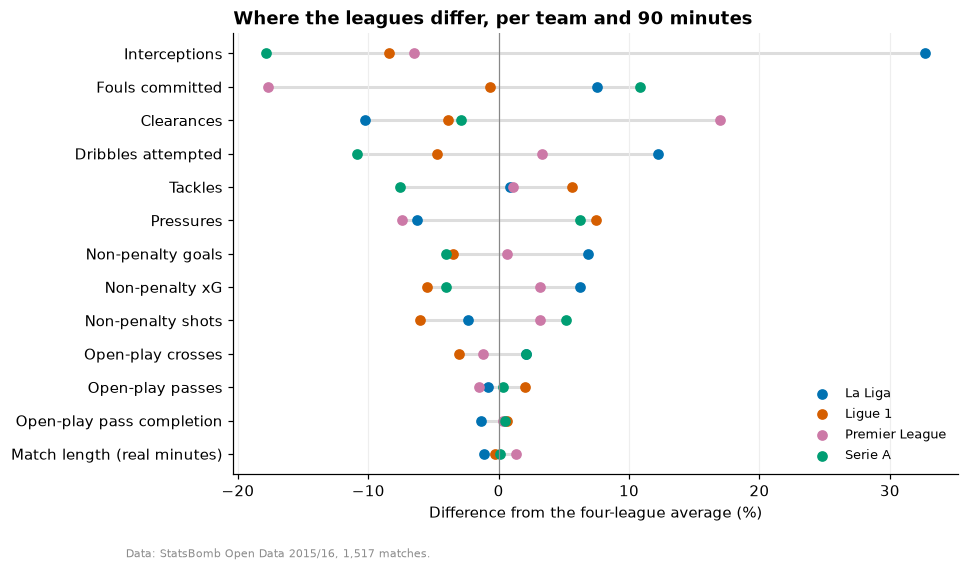

In [19]:
LEAGUES = sorted(team.league.unique())
LEAGUE_COLORS = dict(
    zip(LEAGUES, [OKABE_ITO[0], OKABE_ITO[5], OKABE_ITO[3], OKABE_ITO[2]], strict=True)
)
diff = by_league[LEAGUES].div(by_league["All four"], axis=0).sub(1).mul(100)
order = diff.abs().max(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for i, metric in enumerate(order):
    ax.plot(
        [diff.loc[metric].min(), diff.loc[metric].max()], [i, i], color="#DDDDDD", lw=2, zorder=1
    )
for league in LEAGUES:
    ax.scatter(
        diff.loc[order, league],
        range(len(order)),
        color=LEAGUE_COLORS[league],
        s=36,
        label=league,
        zorder=2,
    )
ax.axvline(0, color="#888888", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.grid(axis="x", color="#EEEEEE")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Difference from the four-league average (%)")
ax.set_title("Where the leagues differ, per team and 90 minutes")
ax.legend(loc="lower right", fontsize=8.5)
credit(fig, "Data: StatsBomb Open Data 2015/16, 1,517 matches.")
plt.show()

### 3.2 A change in how the Premier League was recorded

Interceptions differ far more between leagues than anything else, which is unlikely to be
football. Tracking event counts match week by match week shows why: from **28 December 2015**
(match week 19) the Premier League records about three times as many interceptions per match
and about 18% more pressures, while passes, ball recoveries and duels stay flat. Nothing on the
pitch changes that abruptly; the way the data was collected did.

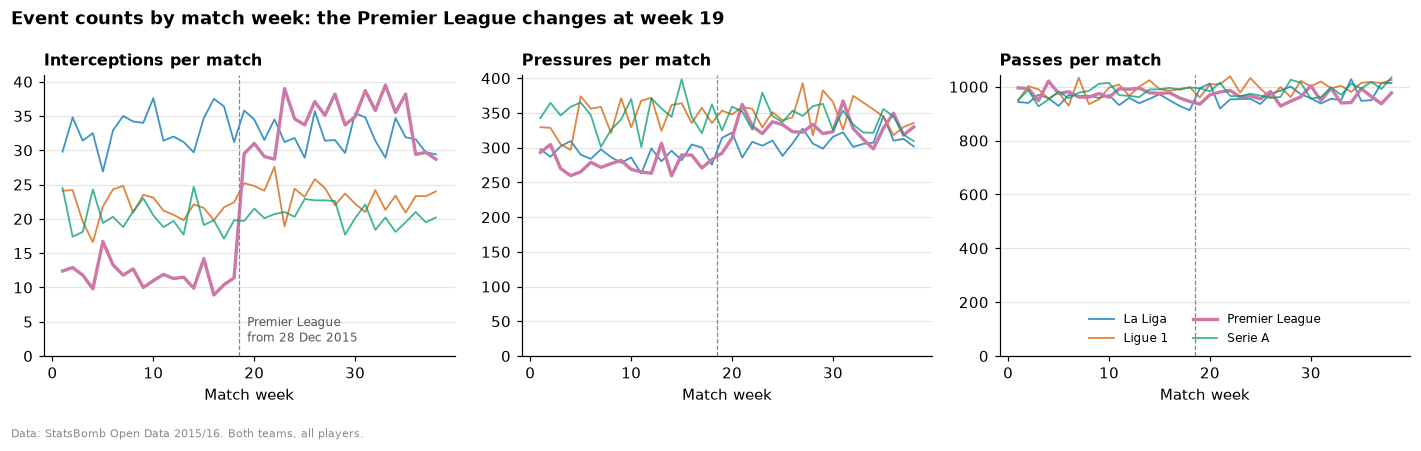

In [20]:
weekly = con.sql("""
    SELECT c.competition_name AS league, m.match_week, count(DISTINCT m.match_id) AS matches,
           count(*) FILTER (WHERE e.type = 'Interception') AS interceptions,
           count(*) FILTER (WHERE e.type = 'Pressure') AS pressures,
           count(*) FILTER (WHERE e.type = 'Pass') AS passes
    FROM matches m
    JOIN competitions c ON c.competition_id = m.competition_id
    JOIN events e ON e.match_id = m.match_id
    WHERE m.scouting_pool
    GROUP BY ALL ORDER BY ALL
""").df()
for m in ("interceptions", "pressures", "passes"):
    weekly[m] = weekly[m] / weekly.matches

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, m in zip(axes, ["interceptions", "pressures", "passes"], strict=True):
    for league in LEAGUES:
        w = weekly[weekly.league == league]
        ax.plot(
            w.match_week,
            w[m],
            color=LEAGUE_COLORS[league],
            label=league,
            lw=2.2 if league == "Premier League" else 1.2,
            alpha=1 if league == "Premier League" else 0.75,
        )
    ax.axvline(18.5, color="#888888", lw=0.8, ls="--")
    ax.set_title(f"{m.capitalize()} per match", fontsize=10.5)
    ax.set_xlabel("Match week")
    ax.set_ylim(0)
axes[0].text(
    19.3, 1.5, "Premier League\nfrom 28 Dec 2015", fontsize=8, va="bottom", color="#555555"
)
axes[2].legend(fontsize=8, loc="lower center", ncol=2)
fig.suptitle(
    "Event counts by match week: the Premier League changes at week 19",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
credit(fig, "Data: StatsBomb Open Data 2015/16. Both teams, all players.")
fig.tight_layout()
plt.show()

The same comparison (match weeks 19–38 against 1–18) for every event type in every
league: outside the Premier League, no event type moves by more than 8%.

In [21]:
screen = (
    con.sql("""
    WITH per AS (
        SELECT c.competition_name AS league, m.match_id, m.match_week, e.type, count(*) AS n
        FROM events e
        JOIN matches m ON m.match_id = e.match_id
        JOIN competitions c ON c.competition_id = m.competition_id
        WHERE m.scouting_pool GROUP BY ALL),
    grid AS (
        SELECT g.league, g.match_id, g.match_week, t.type
        FROM (SELECT DISTINCT league, match_id, match_week FROM per) g
        CROSS JOIN (SELECT DISTINCT type FROM per) t),
    filled AS (
        SELECT grid.*, coalesce(per.n, 0) AS n
        FROM grid LEFT JOIN per USING (league, match_id, type))
    SELECT league, type AS event_type,
           avg(n) FILTER (WHERE match_week <= 18) AS weeks_1_18,
           avg(n) FILTER (WHERE match_week >= 19) AS weeks_19_38
    FROM filled GROUP BY ALL HAVING avg(n) >= 5
""")
    .df()
    .assign(ratio=lambda d: d.weeks_19_38 / d.weeks_1_18)
)
screen.reindex(screen.ratio.sub(1).abs().sort_values(ascending=False).index).head(8).round(2)

,league,event_type,weeks_1_18,weeks_19_38,ratio
48,Premier League,Interception,11.77,34.01,2.89
59,Premier League,Pressure,277.62,327.15,1.18
61,Premier League,Clearance,52.49,60.98,1.16
35,Premier League,Miscontrol,26.85,29.76,1.11
21,Ligue 1,Interception,21.78,23.41,1.07
26,Ligue 1,Block,37.53,40.25,1.07
43,La Liga,Pressure,289.86,309.53,1.07
27,Ligue 1,50/50,5.19,5.52,1.06


### 3.3 How much does the league matter for players?

For outfield players with 900 minutes or more: the share of the variation in each per-90 rate
that the league explains once the comparison group is accounted for (partial η²), and how far
each league sits from the average within the same group.

In [22]:
regular_out = players[(players.minutes >= 900) & (players.comparison_group != "GK")]
player_rates = season.loc[regular_out.player_id].assign(
    league=regular_out.league.to_numpy(), group=regular_out.comparison_group.astype(str).to_numpy()
)


def league_effect(metric: str) -> dict:
    d = player_rates[[metric, "league", "group"]].dropna()
    y = d[metric].to_numpy()
    groups_only = pd.get_dummies(d.group).to_numpy(float)
    with_league = np.hstack(
        [groups_only, pd.get_dummies(d.league, drop_first=True).to_numpy(float)]
    )
    rss = [
        ((y - x @ np.linalg.lstsq(x, y, rcond=None)[0]) ** 2).sum()
        for x in (groups_only, with_league)
    ]
    within = d[metric] - d.groupby("group")[metric].transform("mean")
    pct = within.groupby(d.league).mean() / d.groupby("group")[metric].mean().mean() * 100
    return {"partial η²": (rss[0] - rss[1]) / rss[0], **pct.to_dict()}


PLAYER_METRICS = [*PER_90, "pass_completion"]
effects = pd.DataFrame({LABELS[m]: league_effect(m) for m in PLAYER_METRICS}).T
effects.sort_values("partial η²", ascending=False).round(
    {"partial η²": 3, **dict.fromkeys(LEAGUES, 1)}
)

,partial η²,La Liga,Ligue 1,Premier League,Serie A
Interceptions,0.245,37.0,-9.8,-7.0,-20.4
Pressures,0.080,-6.5,7.1,-8.1,7.1
Clearances,0.080,-7.2,-3.5,18.7,-7.0
Key passes (open play),0.028,-5.7,-8.4,1.7,12.2
Tackles,0.022,2.4,5.6,1.1,-8.9
Blocks,0.021,-4.3,-0.5,-1.7,6.3
Ball recoveries,0.018,-4.0,4.6,-1.7,1.1
Non-penalty shots,0.016,-5.8,-4.5,1.8,8.4
Open-play crosses,0.013,-3.0,-0.9,-8.1,11.6
Touches in the opposition box,0.013,1.6,-7.8,5.9,0.5


### What section 3 shows

- **Attacking output is on one scale.** Once the comparison group is accounted for, the league
  explains almost nothing of a player's non-penalty xG, goals or passes (partial η² ≤ 0.004)
  and little of shots, key passes, crosses or touches in the box (≤ 0.03).
- **Some differences are style.** Pressures run 6–7% above average in Ligue 1 and Serie A and
  6–8% below in La Liga and the Premier League; the Premier League commits 18% fewer fouls
  and makes more clearances; La Liga attempts more dribbles; matches last longest in England
  (96.4 real minutes against 94.1 in Spain).
- **Some differences are recording.** Interceptions per team and match range from 10 (Serie A)
  to 16 (La Liga), and the Premier League's triple from 28 December 2015, together with 18%
  more pressures and 16% more clearances. League explains 25% of the variation in players'
  interceptions. A Premier League player's interceptions, pressures and clearances depend on
  which half of the season the player played in.

Defensive numbers (interceptions above all, then pressures and clearances) are not comparable
across leagues, or within the Premier League across the season, without an adjustment.

**Decision (2026-10-11):** interceptions, pressures and clearances are compared only among
players recorded the same way. There are five recording contexts: La Liga, Serie A, Ligue 1,
and the Premier League before and from 28 December 2015. Within each comparison group, a
player's counts in each context are rescaled so that the context's group average equals the
four-league average; the two parts of a Premier League player's season are rescaled
separately. This also removes real league differences in these three numbers (pressing
intensity, for instance), which cannot be told apart from recording. Attacking and passing
numbers are used as recorded.